In [1]:
# General Imports
import sys
from pathlib import Path
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse, FancyBboxPatch
from matplotlib.ticker import MultipleLocator

# Add project root
project_root = Path.cwd().parents[1]
sys.path.append(str(project_root))

# Internal Imports
from main import model, methods, tools, honeycomb_specific, spin_ice_specific

# Data Path
PROCESSED_DATA_PATH = Path("data/processed")
FIGURES_DATA_PATH = Path("data/figures")

[INFO] TensorNetwork backend set to 'jax'.


### Data Loader

In [2]:
def get_processed_data(unit_cell_id, m_ref):
    assert unit_cell_id in [0,1]
    if unit_cell_id == 0:
        unit_cell_str = "HoneycombUnitCell"
        unit_cell = model.unit_cell.HoneycombUnitCell()
        L1, L2 = 3, 3
    else:
        unit_cell_str = "HoneycombRectangularUnitCell"
        unit_cell = model.unit_cell.HoneycombRectangularUnitCell()
        L1, L2 = 3, 2
    lattice = model.lattice.LatticeFromUnitCell(L1, L2, unit_cell)
    file_name = f"Spectrum"
    file_name += f"_{unit_cell_str}_{m_ref}m_ref"
    file_name += f"_{L1}L1_{L2}L2"
    file_path = PROCESSED_DATA_PATH / f"{file_name}.pkl"
    with open(file_path, "rb") as f:
        data = pickle.load(f)
    return data, lattice, file_name

### Plotter

In [3]:
color = tools.visualization.Colors.BLUE

def plt_spectrum(unit_cell_id, m_ref):
    # Load Data
    data, lattice, file_name = get_processed_data(unit_cell_id, m_ref)
    
    m_ref = data["inputs"]["m_ref"]

    states = data["states"]
    dN_vals = data["dN_vals"]
    E_vals = data["E_vals"]
    degeneracys = data["degeneracys"]
    nonzero_qs = data["nonzero_qs"]
    nonzero_qs_counter = data["nonzero_qs_counter"]

    # Init figure
    tools.visualization.setup_matplotlib_style()
    fig, ax = plt.subplots(figsize=(6, 4))

    # Rescale Energy
    E_min = -lattice.plaquettes.N*m_ref**2/2
    E_rescaled = np.array(E_vals)-E_min

    # Frame limit
    dN_lim = [-2.1, 2.97]
    num_of_lvls_to_show = 5
    E_lim = [-0.5, num_of_lvls_to_show+0.5]

    # Layout
    ax.yaxis.set_major_locator(MultipleLocator(1))
    ax.yaxis.set_minor_locator(MultipleLocator(0.5))
    ax.tick_params(axis='y', which='major', length=6)
    ax.tick_params(axis='y', which='minor', length=3)

    ax.set_ylabel(r"Energy $E/V-m^2N_\mathrm{pl}/2$")
    ax.set_xlabel(r"Particle number deviation $\Delta N=N_\mathrm{filling}-N_\mathrm{filling}^{(m)}$")

    ax.set_xlim(dN_lim)
    ax.set_ylim(E_lim)
    fig.tight_layout()

    # Height / width ratio
    fig.canvas.draw()
    bbox = ax.get_window_extent()
    width, height = bbox.width, bbox.height
    fig_aspect = (height / width)
    lim_aspect = (E_lim[1]-E_lim[0]) / (dN_lim[1]-dN_lim[0])
    f = lim_aspect / fig_aspect

    # Config
    dx_highlight = 0.045
    dx_QP = 0.05
    dy_QP = dx_QP*f

    fontsize = 7

    dx_spectrum_width = 0.08
    dx_between_elements = 0.01
    dx_for_text = 0.16
    dx_distance_to_frame = 0.05
    dy_distance_to_frame = 0.0

    dy_between_row_axis = 0.36
    QP_sign_mult_fact = 0.5

    dx_offset_point_to_box = 0.07
    frame_corner_radius = 0.
    
    # Go thorugh all points of the spectrum
    for dN, E, qs, qs_counts in zip(dN_vals, E_rescaled, nonzero_qs, nonzero_qs_counter):
        plt_spectrum = (dN_lim[0] < dN < dN_lim[1]) and (E_lim[0] <= E <= E_lim[1])
        show_info = (dN_lim[0] < dN < dN_lim[1]) and (0 <= E <= num_of_lvls_to_show)
        if show_info and (dN == 0 and E > num_of_lvls_to_show-1):
            show_info = False

        if plt_spectrum:
            ax.plot(
                dN, E, 
                zorder=0, markersize=2, marker='o', color=tools.visualization.Colors.BLACK)
            ax.hlines(
                E, dN-dx_spectrum_width/2, dN+dx_spectrum_width/2, 
                zorder=0, color=tools.visualization.Colors.BLACK, lw=1)
            if (dN, E) in [(0,0), (0,1), (1,1.5), (2,3)]:
                circle = Ellipse(
                    (dN, E), 2*dx_highlight, 2*dx_highlight*f, 
                    zorder=0, fill=False, color=color, lw=0.5)
                ax.add_patch(circle)

        if show_info:
            num_of_rows = len(qs)
            max_row_width = 0
            for row_id in range(num_of_rows):
                max_row_width = max(max_row_width, len(qs[row_id]))
            box_width = max_row_width* (dx_for_text+2*dx_QP + dx_between_elements) - dx_between_elements
            box_height = num_of_rows*dy_between_row_axis+2*dy_distance_to_frame
            
            indiv_offset = -0.15
            if E-abs(dN)*1.5 < num_of_lvls_to_show-1:
                indiv_offset = -0.1
            else:
                indiv_offset = 0.35

            current_y = E - box_height/2 + dy_between_row_axis/2 + indiv_offset
            for row_id in range(num_of_rows):
                num_of_qs = len(qs[row_id])
                current_x = dN + dx_offset_point_to_box + dx_distance_to_frame/2
                for circle_id in range(num_of_qs):
                    q, count = qs[row_id][circle_id], qs_counts[row_id][circle_id]
                    # Add text showing the number of plaquette occupations
                    ax.text(
                        current_x+dx_for_text/2, current_y, f"{count}×",
                        zorder=2, ha="center", va="center", fontsize=fontsize).set_clip_on(True)
                    current_x += dx_for_text+dx_QP
                    num_of_rings = abs(q)
                    # For each QP in a plaquette plot a ring
                    for j in range(num_of_rings):
                        rx = 2*dx_QP*(1+j*2/5)
                        ry = rx*f
                        circle = Ellipse(
                            (current_x, current_y), rx, ry , 
                            fill=False, lw=0.5, zorder=2)
                        ax.add_patch(circle)
                    # Plot the sign of the charge in the middle of the ring
                    ax.plot(
                        [current_x-dx_QP*QP_sign_mult_fact, current_x+dx_QP*QP_sign_mult_fact], 
                        [current_y, current_y],
                        zorder=2, color=tools.visualization.Colors.BLACK, lw=0.5)
                    if q > 0:
                        ax.plot(
                            [current_x, current_x], 
                            [current_y-dy_QP*QP_sign_mult_fact, current_y+dy_QP*QP_sign_mult_fact], 
                            zorder=2, color=tools.visualization.Colors.BLACK, lw=0.5)
                    current_x += dx_QP+dx_between_elements
                current_y += dy_between_row_axis

            if max_row_width != 0:
                # Plot frame
                frame_width = box_width+dx_distance_to_frame+dx_distance_to_frame/2
                frame_height = box_height+2*dy_distance_to_frame
                x_box, y_box = dN+dx_offset_point_to_box, E-box_height/2+indiv_offset
                rounded_rect = FancyBboxPatch(
                    (x_box, y_box), frame_width, frame_height,
                    zorder=1, boxstyle=f"round,pad=0,rounding_size={frame_corner_radius}",
                    mutation_scale=4, edgecolor=tools.visualization.Colors.GRAY, 
                    facecolor=tools.visualization.Colors.NONE, lw=0.5)
                ax.add_patch(rounded_rect)
                # Lines between rows
                y_hline = y_box+dy_distance_to_frame
                for row_id in range(num_of_rows-1):
                    y_hline += dy_between_row_axis
                    ax.hlines(
                        y_hline, x_box, x_box+frame_width, 
                        zorder=1, color=tools.visualization.Colors.GRAY, lw=0.5)
                # Line to frame
                ax.plot(
                    [dN, x_box],[E, y_box+frame_height/2], 
                    zorder=0, color=tools.visualization.Colors.GRAY, lw=0.5)
    
    return fig, ax, file_name

### Plotting HoneycombRectangularUnitCell

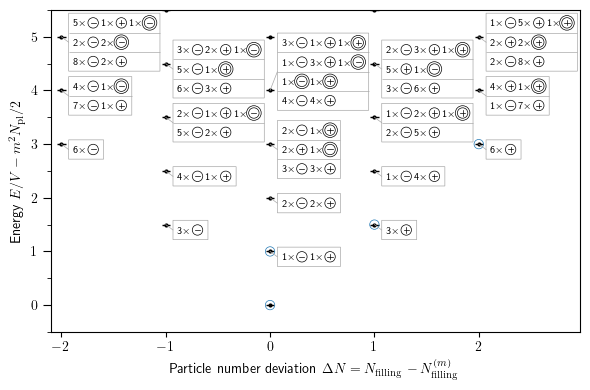

In [4]:
fig, ax, file_name  = plt_spectrum(1, 3)

# Save
file_path = FIGURES_DATA_PATH / f"{file_name}"
fig.savefig(f"{file_path}.pdf")
plt.show()

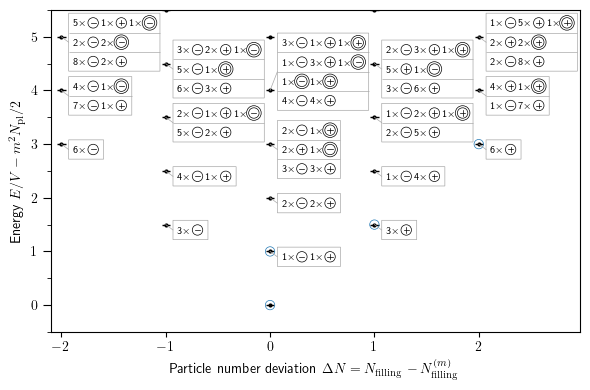

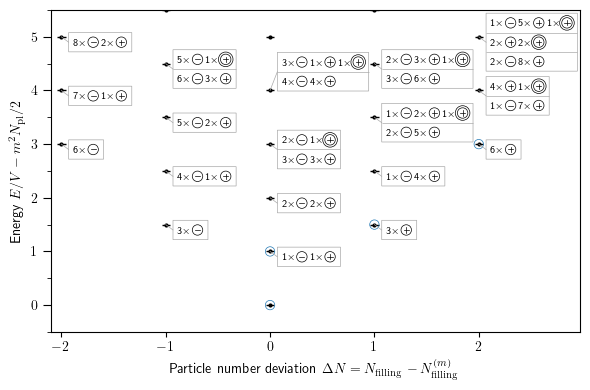

In [5]:
fig, ax, file_name  = plt_spectrum(1, 2)
plt.show()
fig, ax, file_name  = plt_spectrum(1, 1)
plt.show()

### Plotting HoneycombUnitCell

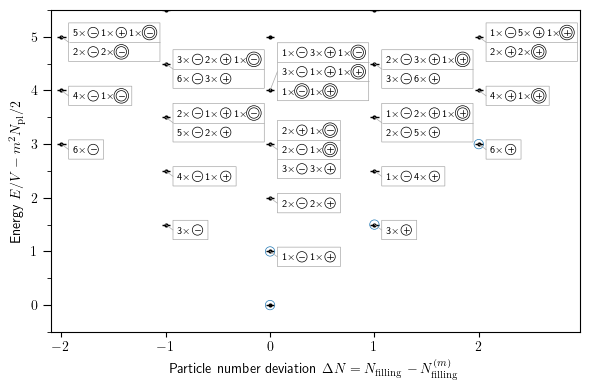

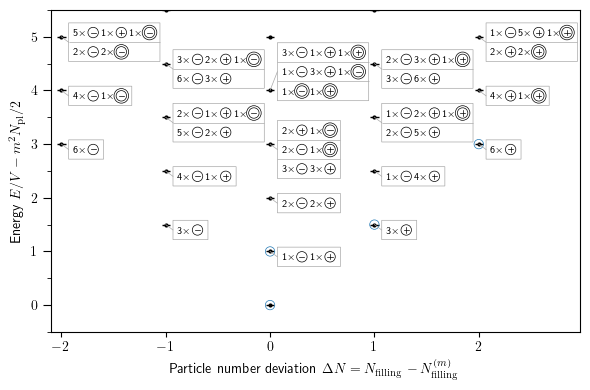

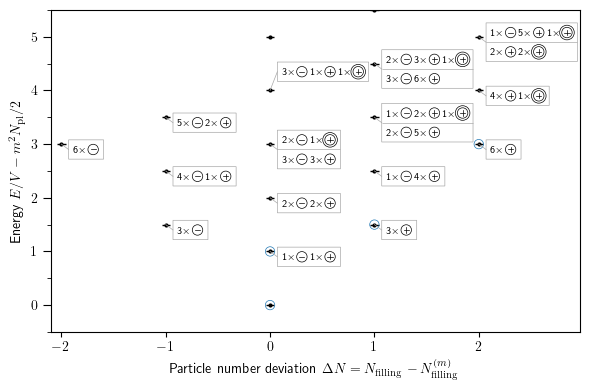

In [6]:
fig, ax, file_name = plt_spectrum(0, 3)
plt.show()
fig, ax, file_name = plt_spectrum(0, 2)
plt.show()
fig, ax, file_name = plt_spectrum(0, 1)
plt.show()